In [1]:
# import libraries
import mne, os, glob, pickle
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

In [2]:
main_dir = '/Users/cl2030/Library/CloudStorage/OneDrive-RutgersUniversity/projects/PEERS/'
data_dir = os.path.join(main_dir, 'data')

In [3]:
subj = 'sub-LTP327'
task = 'task-ltpFR2'
sess = 'ses-0'
fname = os.path.join(data_dir, '%s', '%s', 'beh-enc_%s_%s_%s.csv') %(subj, sess, subj, sess, task)
df_enc = pd.read_csv(fname)
df_enc

,subject,trial_type,trial,item_name,item_num,sample,onset
0,LTP327,WORD,1.0,COOKBOOK,373.0,312324,624.648
1,LTP327,WORD,1.0,HOOK,715.0,313590,627.180
2,LTP327,WORD,1.0,SLIDE,1326.0,314881,629.762
3,LTP327,WORD,1.0,PEBBLE,1035.0,316247,632.494
4,LTP327,WORD,1.0,BACKBONE,66.0,317646,635.292
...,...,...,...,...,...,...,...
571,LTP327,WORD,24.0,JELLY,755.0,2846087,5692.174
572,LTP327,WORD,24.0,BUGGY,188.0,2847320,5694.640
573,LTP327,WORD,24.0,DUST,508.0,2848544,5697.088
574,LTP327,WORD,24.0,DUSTPAN,509.0,2849810,5699.620


In [4]:
fname = os.path.join(data_dir, '%s', '%s', 'beh-rec_%s_%s_%s.csv') %(subj, sess, subj, sess, task)
df_rec = pd.read_csv(fname)
df_rec = df_rec[df_rec.trial_sample > 0]

# update dataframe
# treat bad epochs' RT as 0
RT_update = df_rec.resp_time.values * df_rec.resp_acc.values
df_rec['RT_update'] = RT_update
df_rec

,subject,trial_type,block,item_name,trial_sample,speech_sample,trial_onset,speech_onset,resp_time,resp_acc,enc_pos,RT_update
0,LTP327,REC_WORD,1.0,BACKBONE,356321,357027,712642.0,714054.0,1412.0,1,4.0,1412.0
1,LTP327,REC_WORD,1.0,MARROW,357027,357671,714054.0,715342.0,1288.0,1,5.0,1288.0
2,LTP327,REC_WORD,1.0,COOKBOOK,357671,358264,715342.0,716528.0,1186.0,1,0.0,1186.0
3,LTP327,REC_WORD,1.0,AWARD,358264,358829,716528.0,717658.0,1130.0,1,6.0,1130.0
4,LTP327,REC_WORD,1.0,HOOK,358829,359493,717658.0,718986.0,1328.0,1,1.0,1328.0
...,...,...,...,...,...,...,...,...,...,...,...,...
453,LTP327,REC_WORD,24.0,NOVEL,2880948,2882224,5761896.0,5764448.0,2552.0,1,7.0,2552.0
454,LTP327,REC_WORD,24.0,NOTEBOOK,2882224,2882859,5764448.0,5765718.0,1270.0,1,6.0,1270.0
455,LTP327,REC_WORD,24.0,STUDY,2882859,2883572,5765718.0,5767144.0,1426.0,0,NaN,0.0
456,LTP327,REC_WORD,24.0,COURSE,2883572,2884406,5767144.0,5768812.0,1668.0,1,18.0,1668.0


In [5]:
# construct events for later preprocessing
n_events = df_rec.shape[0]
events_rec = np.zeros((n_events, 3))
events_rec[:,0] = df_rec['trial_sample'].values
events_rec[:,2] = 1
events_rec = events_rec.astype(int)
events_rec

array([[ 356321,       0,       1],
       [ 357027,       0,       1],
       [ 357671,       0,       1],
       ...,
       [2882859,       0,       1],
       [2883572,       0,       1],
       [2884406,       0,       1]], shape=(458, 3))

In [6]:
fname = os.path.join(data_dir, '%s', '%s', '%s_%s_ICA-raw.fif') %(subj, sess, subj, sess)
raw = mne.io.read_raw(fname, preload=True)

Opening raw data file /Users/cl2030/Library/CloudStorage/OneDrive-RutgersUniversity/projects/PEERS/data/sub-LTP327/ses-0/sub-LTP327_ses-0_ICA-raw.fif...
    Range : 0 ... 2935999 =      0.000 ...  5871.998 secs
Ready.
Reading 0 ... 2935999  =      0.000 ...  5871.998 secs...


In [7]:
# define epoch parameters
epoch_tmin     = -0.2
epoch_tmax     = 3
epoch_baseline = None
detrend        = 1 # linear detrend
decim          = 1 # 1 for no decimation (downsampling)

# define event id
event_id = dict(Word = 1)

# epoching
info   = raw.info
picks  = mne.pick_types(info, meg=False, eeg=True, eog=False, stim=False)
epochs_rec = mne.Epochs(raw,
                    events   = events_rec, 
                    event_id = event_id,
                    picks    = picks,
                    decim    = decim,
                    tmin     = epoch_tmin,
                    tmax     = epoch_tmax,
                    baseline = epoch_baseline,
                    detrend  = detrend,
                    preload  = True,
                    reject_by_annotation = False)

epochs_rec.metadata = df_rec

Not setting metadata
458 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 458 events and 1601 original time points ...
0 bad epochs dropped
Adding metadata with 12 columns


In [8]:
# construct events for later preprocessing
n_events = df_enc.shape[0]
events_enc = np.zeros((n_events, 3))
events_enc[:,0] = df_enc['sample'].values
events_enc[:,2] = 1
events_enc = events_enc.astype(int)
events_enc

array([[ 312324,       0,       1],
       [ 313590,       0,       1],
       [ 314881,       0,       1],
       ...,
       [2848544,       0,       1],
       [2849810,       0,       1],
       [2851068,       0,       1]], shape=(576, 3))

In [9]:
# define epoch parameters
epoch_tmin     = -0.2
epoch_tmax     = 0
epoch_baseline = None
detrend        = 1 # linear detrend
decim          = 1 # 1 for no decimation (downsampling)

# define event id
event_id = dict(Word = 1)

# epoching
info   = raw.info
picks  = mne.pick_types(info, meg=False, eeg=True, eog=False, stim=False)
epochs_enc = mne.Epochs(raw,
                    events   = events_enc, 
                    event_id = event_id,
                    picks    = picks,
                    decim    = decim,
                    tmin     = epoch_tmin,
                    tmax     = epoch_tmax,
                    baseline = epoch_baseline,
                    detrend  = detrend,
                    preload  = True,
                    reject_by_annotation = False)

# epochs.info['bads'] = ['E45']
# epochs.interpolate_bads()

epochs_enc.metadata = df_enc

Not setting metadata
576 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 576 events and 101 original time points ...
0 bad epochs dropped
Adding metadata with 7 columns


In [10]:
# update baseline data
data_rec_mtx = epochs_rec.get_data().copy()
data_enc_mtx = epochs_enc.get_data().copy()
n_events_rec = data_rec_mtx.shape[0]

for i in range(n_events_rec):
    # find epoch index
    epoch_idx = np.where((epochs_enc.metadata.trial == epochs_rec.metadata.iloc[i].block) & 
                         (epochs_enc.metadata.item_name == epochs_rec.metadata.iloc[i].item_name))[0]
    
    if len(epoch_idx) > 0:
        pass
    else:
        trl_arr = np.arange(0, 24)                                           # create an array 0-23
        miss_pos = np.setdiff1d(trl_arr, df_rec[df_rec.block == 
                                epochs_rec.metadata.iloc[i].block].enc_pos)  # find missing indices (not recalled)
        rng = np.random.default_rng(1119)
        rng_pos = rng.choice(miss_pos)                                       # randomly choose one missing index
        target_item = df_enc[df_enc.trial == epochs_rec.metadata.iloc[i].block].iloc[rng_pos].item_name
        epoch_idx = np.where((epochs_enc.metadata.trial == epochs_rec.metadata.iloc[i].block) & 
                         (epochs_enc.metadata.item_name == target_item))[0]
    
    
    # update baseline period
    data_rec_mtx[i,:,:100] = data_enc_mtx[epoch_idx,:,:100]


In [11]:
# update epochs and baseline correction
epochs_rec._data = data_rec_mtx
baseline=(-0.2, -0.002)
epochs_rec.apply_baseline(baseline=baseline)

# save epochs
fname = os.path.join(data_dir, '%s', '%s', '%s_%s-epo.fif') %(subj, sess, subj, sess)
epochs_rec.save(fname, overwrite=True)

Applying baseline correction (mode: mean)
Overwriting existing file.
Overwriting existing file.
Overwriting existing file.


[PosixPath('/Users/cl2030/Library/CloudStorage/OneDrive-RutgersUniversity/projects/PEERS/data/sub-LTP327/ses-0/sub-LTP327_ses-0-epo.fif')]

No projector specified for this dataset. Please consider the method self.add_proj.


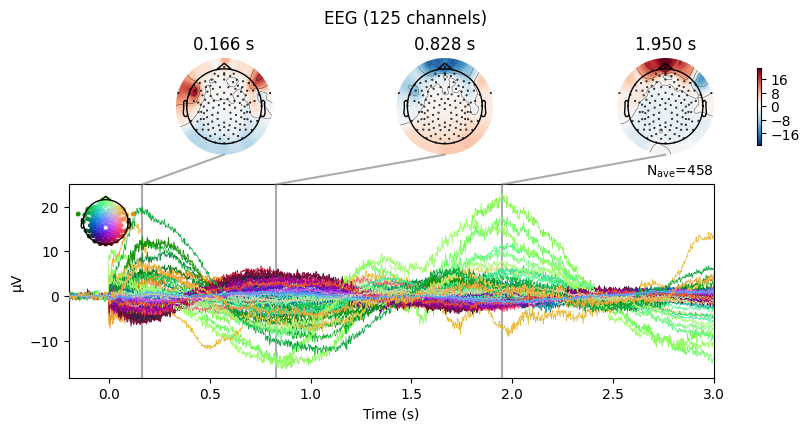

In [12]:
# epochs_rec.info['bads'] = ['E49']
# epochs_rec.interpolate_bads()
evk = epochs_rec.average()
f = evk.plot_joint()